# Banco Aurora — auditoria, cinco modelos e decisão por custo

**Autora:** Mayumi Castiglioni. **Parte 1 — etapas de análise e escolha do candidato.**

Este notebook contém código para ler os CSVs originais, validar o contrato, separar os períodos, treinar novamente os cinco modelos, testar os 99 cortes e justificar a escolha. As saídas salvas foram produzidas executando todas as células em ordem. Ele não depende de resultados JSON anteriores, de Postgres ou de uma API aberta para fazer a comparação.

**Escopo:** cobre auditoria, pré-processamento, comparação, threshold e decisão (seções 1–6 da atividade). Este notebook cobre a análise e seleção. O notebook `parte1.ipynb` e os documentos de entrega cobrem as etapas posteriores de monitoramento, promoção, paridade com API e empacotamento; E03 está em produção como `antifraude@champion`.

## Como reproduzir

Use Python 3.11, instale `requirements.txt` em um ambiente virtual e selecione esse ambiente no Jupyter. Abra o notebook na pasta do projeto ou na pasta de entrega, reinicie o kernel e execute **Run All**. O processo realmente retreina os cinco modelos; pode levar alguns minutos. Os CSVs devem estar em `dados/`, com os nomes originais. O pacote local de entrega inclui esses arquivos; o Git não inclui dados brutos.

O MLflow usa por padrão uma pasta temporária local, em caminho curto para Windows. Não precisa de servidor. É possível informar `AURORA_TRACKING_URI` para usar um servidor existente; cada execução cria um experimento separado e não promove modelos. Resultados, manifesto, curvas e resumo são gravados em `resultados_reproducao/<execução>/`, sem apagar execuções anteriores. Tempos variam por máquina; métricas são conferidas contra as evidências originais quando disponíveis.

In [1]:
import os, sys, json, time, hashlib, tempfile, platform, inspect
from pathlib import Path
from datetime import datetime, timezone
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import mlflow
from mlflow.models import infer_signature
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier

candidatos_raiz = [Path.cwd(), Path.cwd().parent]
ROOT = next((p for p in candidatos_raiz if (p/'features.py').exists() and (p/'contrato/contrato_features.yaml').exists()), None)
assert ROOT is not None, 'Abra o notebook a partir da pasta do projeto ou de entrega.'
sys.path.insert(0, str(ROOT))
from features import construir
from monitoramento import custo, medir

EXECUCAO = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
SAIDA = ROOT / 'resultados_reproducao' / EXECUCAO
SAIDA.mkdir(parents=True, exist_ok=False)
versoes = {p: metadata.version(p) for p in ['scikit-learn','mlflow','pandas','numpy','scipy','pyyaml','matplotlib','nbformat','nbclient','ipykernel']}
print('Python:', platform.python_version())
display(pd.Series(versoes, name='versão').to_frame())
assert metadata.version('scikit-learn') == '1.8.0', 'Use as versões de requirements.txt.'
assert metadata.version('mlflow') == '2.19.0', 'Use MLflow 2.19.0 para esta reprodução.'
np.random.seed(42)

Python: 3.11.2


,versão
scikit-learn,1.8.0
mlflow,2.19.0
pandas,2.3.3
numpy,2.1.0
scipy,1.17.1
pyyaml,6.0.3
matplotlib,3.10.7
nbformat,5.10.4
nbclient,0.10.2
ipykernel,6.29.5


## 1. Dados e contrato: conferir antes de treinar

IDs são lidos como texto para preservar zeros iniciais. A junção é externa e exige cardinalidade 1:1: nenhuma linha pode desaparecer silenciosamente. Somente as 13 features do YAML entram no modelo; `id_transacao`, `id_cliente`, `semana`, datas e rótulo são metadados ou alvo.

Validamos o histórico com várias semanas diretamente; o validador de upload do sistema exige uma única semana por arquivo. Além dos tipos, verificamos as regras semânticas que o YAML ainda não automatiza. Não imputamos nem excluímos registros sem evidência de necessidade.

In [2]:
contrato = yaml.safe_load((ROOT/'contrato/contrato_features.yaml').read_text(encoding='utf-8'))
FEATURES = [f['nome'] for f in contrato['features']]
assert len(FEATURES) == 13 and len(set(FEATURES)) == 13
transacoes_path = ROOT/'dados/transacoes_semanas_01_12.csv'
rotulos_path = ROOT/'dados/rotulos_semanas_01_12.csv'
assert transacoes_path.exists() and rotulos_path.exists(), 'Extraia os dois CSVs do ZIP original para dados/.'
transacoes = pd.read_csv(transacoes_path, dtype={'id_transacao':str,'id_cliente':str})
rotulos = pd.read_csv(rotulos_path, dtype={'id_transacao':str})
assert transacoes.id_transacao.notna().all() and rotulos.id_transacao.notna().all()
assert transacoes.id_transacao.is_unique and rotulos.id_transacao.is_unique
assert set(contrato['metadados'] + FEATURES) <= set(transacoes)
assert rotulos.fraude.isin([0,1]).all()
dados = transacoes.merge(rotulos, on='id_transacao', how='outer', validate='one_to_one', indicator=True)
assert dados['_merge'].eq('both').all()
assert len(dados) == len(transacoes) == len(rotulos)
hashes = {p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in [transacoes_path,rotulos_path,ROOT/'contrato/contrato_features.yaml']}
print('Transações:',len(transacoes),'Rótulos:',len(rotulos),'Junção sem perdas:',len(dados))
display(pd.Series(hashes,name='SHA-256').to_frame())
display(pd.DataFrame(contrato['features'])[['nome','tipo']])

Transações: 240384 Rótulos: 240384 Junção sem perdas: 240384


,SHA-256
transacoes_semanas_01_12.csv,2a21363ee7499a646dd0e04288bba0b81abf87aad4a34c...
rotulos_semanas_01_12.csv,bafda7607bd7dc6b724a757aea94c384f1f155d051880c...
contrato_features.yaml,5084b6bb26ff22145ec15970aac7a2597ef8a5993c327a...


,nome,tipo
0,valor_transacao,float
1,hora_transacao,int
2,dia_semana,int
3,canal,categoria
4,dispositivo_novo,bool
5,qtd_transacoes_1h,int
6,valor_medio_30d,float
7,razao_valor_media,float
8,distancia_ultima_transacao_km,float
9,idade_conta_dias,int


In [3]:
verificacoes = []
for f in contrato['features']:
    s = dados[f['nome']]
    erros = int(s.isna().sum())
    if f['tipo'] == 'categoria':
        erros += int((~s.isin(f['valores']) & s.notna()).sum())
    else:
        num = pd.to_numeric(s, errors='coerce')
        erros += int((~np.isfinite(num)).sum())
        if f['tipo'] in ('int','bool'):
            erros += int((num.dropna() % 1 != 0).sum())
        if f['tipo'] == 'bool': erros += int((~num.isin([0,1])).sum())
        if 'min' in f: erros += int((num < f['min']).sum())
        if 'max' in f: erros += int((num > f['max']).sum())
    verificacoes.append({'feature':f['nome'],'violações':erros})
validacao_contrato = pd.DataFrame(verificacoes)
display(validacao_contrato)
assert validacao_contrato['violações'].sum() == 0
assert dados[contrato['metadados']].notna().all().all()
datas = pd.to_datetime(dados.data_transacao, errors='coerce')
assert datas.notna().all()
assert (datas.dt.hour == dados.hora_transacao).all()
assert (datas.dt.dayofweek == dados.dia_semana).all()
assert np.isclose(dados.razao_valor_media, dados.valor_transacao/dados.valor_medio_30d, atol=0.000051, rtol=0).all()
# A tolerância é absoluta e cobre arredondamento da razão a quatro casas.
fraude = dados.fraude.eq(1)
contestacoes = pd.to_datetime(dados.data_contestacao, errors='coerce')
assert contestacoes[fraude].notna().all()
assert (contestacoes[fraude] >= datas[fraude]).all()
print('Erro máximo da razão:', (dados.razao_valor_media-dados.valor_transacao/dados.valor_medio_30d).abs().max())
display(dados.assign(contestacao_ausente=contestacoes.isna()).groupby('fraude').agg(n=('fraude','size'),contestacoes_ausentes=('contestacao_ausente','sum')))

,feature,violações
0,valor_transacao,0
1,hora_transacao,0
2,dia_semana,0
3,canal,0
4,dispositivo_novo,0
5,qtd_transacoes_1h,0
6,valor_medio_30d,0
7,razao_valor_media,0
8,distancia_ultima_transacao_km,0
9,idade_conta_dias,0


Erro máximo da razão:

 5.000000000077165e-05


,n,contestacoes_ausentes
fraude,,
0,236886,236886
1,3498,0


**Interpretação da auditoria:** ausência de data de contestação nos legítimos não é ausência do rótulo, pois a classe 0 está explicitamente presente. Não removemos essas transações. Para semanas futuras, rótulo ausente continua desconhecido, sem conversão para zero. As verificações não provam que médias, contagens e distâncias foram calculadas apenas com informações disponíveis no momento da transação: essa disponibilidade upstream é uma limitação declarada.

## 2. Separação temporal e população avaliada

Treino nas semanas 1–10 e validação nas semanas 11–12, conforme exigido. Uma divisão aleatória misturaria períodos e enfraqueceria a simulação de prever o futuro. Clientes podem reaparecer em períodos posteriores; seus IDs não entram no modelo. Essa avaliação não demonstra, isoladamente, generalização para clientes inéditos.

In [4]:
assert set(dados.semana.unique()) == set(range(1,13))
treino = dados[dados.semana.between(1,10)].copy()
validacao = dados[dados.semana.isin([11,12])].copy()
assert len(treino)+len(validacao)==len(dados)
assert set(treino.id_transacao).isdisjoint(set(validacao.id_transacao))
assert pd.to_datetime(treino.data_transacao).max() < pd.to_datetime(validacao.data_transacao).min()
X_treino, y_treino = treino[FEATURES], treino.fraude
X_validacao, y_validacao = validacao[FEATURES], validacao.fraude
valores = validacao.valor_transacao.to_numpy()
print('Treino:',len(treino),'Validação:',len(validacao))
display(dados.groupby('semana').agg(transacoes=('fraude','size'),fraudes=('fraude','sum'),taxa_fraude=('fraude','mean')))

Treino: 200887 Validação: 39497


,transacoes,fraudes,taxa_fraude
semana,,,
1,20160,297,0.014732
2,19811,282,0.014235
3,20283,249,0.012276
4,19995,263,0.013153
5,20318,371,0.018260
6,20479,298,0.014551
7,20307,277,0.013641
8,19706,306,0.015528
9,20006,234,0.011696


## 3. Função de custo e pré-processamento reutilizáveis

Custo = valor das fraudes aprovadas + R$ 15 × número de transações legítimas bloqueadas. Bloquear significa encaminhar para verificação. O custo usa quantidade de transações; a justificativa final também informa clientes distintos afetados. Acurácia não decide a escolha.

O código abaixo mostra as funções efetivamente importadas. O Pipeline inclui todo o pré-processamento: categorias e ordem vêm do contrato, OneHotEncoder recebe a lista completa de categorias válidas, somente a regressão logística escala numéricas e todos os ajustes ocorrem apenas no treino. Assim, uma UF prevista no contrato, mas ausente no treino, mantém representação consistente. Uma categoria fora do contrato é erro, não imputação silenciosa.

In [5]:
print(inspect.getsource(custo))
print(inspect.getsource(medir))
print(inspect.getsource(construir))
assert custo([1,0,1,0],[0,1,1,0],[200,100,300,50]) == 215
assert custo([1,0],[0,0],[200,100]) == 200
assert custo([1,0],[1,1],[200,100]) == 15
assert medir([1,0],[0.10,0.10],[200,100],0.10)['custo'] == 15
print('Casos conhecidos do custo e regra score >= threshold verificados.')

def custo(real, bloquear, valores):
    y, b, v = np.asarray(real), np.asarray(bloquear), np.asarray(valores, dtype=float)
    if not (len(y) == len(b) == len(v)) or len(y) == 0:
        raise ValueError("Vetores devem ter mesmo tamanho não vazio")
    if not np.isin(y, [0, 1]).all() or not np.isin(b, [0, 1]).all() or not np.isfinite(v).all() or (v < 0).any():
        raise ValueError("Rótulos e decisões binários, valores finitos e não negativos são obrigatórios")
    b = b.astype(bool)
    return float(v[(y == 1) & ~b].sum() + 15 * ((y == 0) & b).sum())

def medir(real, score, valores, threshold):
    y, s, v = np.asarray(real), np.asarray(score), np.asarray(valores)
    if len(s) != len(y) or not np.isfinite(s).all() or ((s < 0) | (s > 1)).any() or not 0 <= threshold <= 1:
        raise ValueError("Scores e threshold devem ser finitos entre zero e um")
    b = s >= threshold
    return dict(custo=custo(y,b,v), recall=float(recall_score(y,b,zero_division=0)), precision=float(precision

## 4. Hipóteses e protocolo definidos antes dos resultados

Uma configuração por família, sem busca de hiperparâmetros, reamostragem, pesos de classe ou calibração adicionais. O orçamento é cinco treinos. A finalidade é contrastar hipóteses distintas, não aumentar tentativas até obter uma validação favorável.

| ID | Família | Hipótese inicial | Limitação prevista |
|---|---|---|---|
| E01 | Regressão logística | Referência aditiva, rápida e explicável | Pode não capturar interações |
| E02 | Árvore limitada | Relações não lineares por regras simples | Instabilidade e folhas com scores grosseiros |
| E03 | Random Forest | Agregação de árvores reduz variância e captura interações | Tempo de treino e necessidade de escolher corte |
| E04 | Extra Trees | Cortes mais aleatórios podem melhorar generalização ou velocidade | Podem elevar viés |
| E05 | HistGradientBoosting | Boosting corrige erros sucessivos e captura padrões complementares | Codificação, memória e estabilidade precisam ser conferidas |

Para cada família, varremos 99 cortes globais de 0,01 a 0,99. Critério: menor custo agregado de 11–12; empate a centavos → menor taxa de bloqueio → menor corte. A escolha entre famílias usa custo, analisando também cada semana. Average precision é a definição adotada de PR-AUC (não área trapezoidal da curva). As semanas 11–12 são usadas na seleção, portanto não são teste independente. Mais tentativas aumentariam o risco de seleção otimista.

**Histórico preservado:** na rodada anterior houve uma falha técnica E01 antes do treino, causada pelo caminho de artefatos e codificação de console no Windows. Ela não demonstra desempenho ruim do modelo. O arquivo `tentativa-tecnica-inicial.json` e as runs originais seguem no pacote. Esta nova rodada é uma reprodução das mesmas cinco configurações, não cinco novas hipóteses.

In [6]:
modelos = {
 'E01': (LogisticRegression(max_iter=1000,random_state=42), True),
 'E02': (DecisionTreeClassifier(max_depth=8,min_samples_leaf=50,random_state=42), False),
 'E03': (RandomForestClassifier(n_estimators=150,max_depth=12,min_samples_leaf=20,n_jobs=2,random_state=42), False),
 'E04': (ExtraTreesClassifier(n_estimators=150,max_depth=12,min_samples_leaf=20,n_jobs=2,random_state=42), False),
 'E05': (HistGradientBoostingClassifier(max_iter=150,max_leaf_nodes=15,l2_regularization=1,random_state=42), False),
}
configuracoes = {k:{'algoritmo':type(m).__name__,'escalar':esc,'parametros':m.get_params()} for k,(m,esc) in modelos.items()}
display(pd.DataFrame([{'id':k,**v} for k,v in configuracoes.items()]))
mlflow_local = Path(tempfile.gettempdir())/'aurora_mlflow_repro'
mlflow_local.mkdir(parents=True,exist_ok=True)
tracking_uri = os.environ.get('AURORA_TRACKING_URI', mlflow_local.as_uri())
mlflow.set_tracking_uri(tracking_uri)
artefatos_mlflow = Path(tempfile.gettempdir())/'aurora_repro_artifacts'/EXECUCAO
artefatos_mlflow.mkdir(parents=True,exist_ok=True)
experimento_id = mlflow.create_experiment('aurora_reproducao_'+EXECUCAO,artifact_location=artefatos_mlflow.as_uri())
manifesto = {'execucao_utc':EXECUCAO,'python':platform.python_version(),'versoes':versoes,'hashes':hashes,'treino_semanas':list(range(1,11)),'validacao_semanas':[11,12],'linhas_treino':len(treino),'linhas_validacao':len(validacao),'tracking_tipo':'servidor informado' if 'AURORA_TRACKING_URI' in os.environ else 'arquivo local temporario','experimento_id':experimento_id,'configuracoes':configuracoes}
(SAIDA/'manifesto.json').write_text(json.dumps(manifesto,indent=2,ensure_ascii=False),encoding='utf-8')
resultados, pipelines, scores, curvas, runs = {}, {}, {}, {}, {}

,id,algoritmo,escalar,parametros
0,E01,LogisticRegression,True,"{'C': 1.0, 'class_weight': None, 'dual': False..."
1,E02,DecisionTreeClassifier,False,"{'ccp_alpha': 0.0, 'class_weight': None, 'crit..."
2,E03,RandomForestClassifier,False,"{'bootstrap': True, 'ccp_alpha': 0.0, 'class_w..."
3,E04,ExtraTreesClassifier,False,"{'bootstrap': False, 'ccp_alpha': 0.0, 'class_..."
4,E05,HistGradientBoostingClassifier,False,"{'categorical_features': 'from_dtype', 'class_..."


In [7]:
def executar_modelo(identificador):
    modelo, escalar = modelos[identificador]
    pipeline = construir(modelo, contrato, escalar)
    # Nenhum fit em validação: Pipeline aprende todos os parâmetros em 1–10.
    with mlflow.start_run(experiment_id=experimento_id,run_name=identificador+'_reproducao') as run:
        mlflow.set_tags({'tipo':'reproducao','hipotese_id':identificador,'promovido':'false'})
        mlflow.log_params({'algoritmo':type(modelo).__name__,'escalar':escalar,'semanas_treino':'1-10','semanas_validacao':'11-12','contrato':contrato['versao'],**modelo.get_params()})
        inicio = time.perf_counter()
        pipeline.fit(X_treino,y_treino)
        treino_s = time.perf_counter()-inicio
        inicio = time.perf_counter()
        prob = pipeline.predict_proba(X_validacao)[:,list(pipeline.classes_).index(1)]
        inferencia_s = time.perf_counter()-inicio
        assert len(prob)==len(validacao) and np.isfinite(prob).all()
        curva = pd.DataFrame([{'threshold':float(t),**medir(y_validacao,prob,valores,t)} for t in np.arange(1,100)/100])
        ordem = curva.assign(custo_centavos=curva.custo.round(2)).sort_values(['custo_centavos','taxa_bloqueio','threshold'],kind='stable')
        melhor = ordem.iloc[0]
        corte = float(melhor.threshold)
        metricas = medir(y_validacao,prob,valores,corte)
        registro = {'id':identificador,'algoritmo':type(modelo).__name__,'threshold':corte,**metricas,'treino_segundos':treino_s,'inferencia_segundos':inferencia_s,'run_id':run.info.run_id}
        mlflow.log_metrics({k:v for k,v in registro.items() if isinstance(v,(int,float))})
        mlflow.sklearn.log_model(pipeline,artifact_path='modelo',signature=infer_signature(X_treino,pipeline.predict(X_treino)),input_example=X_treino.head(3),code_paths=[str(ROOT/'features.py')],pip_requirements=[f'{nome}=={versoes[nome]}' for nome in ['scikit-learn','pandas','numpy','scipy']])
        curva.to_csv(SAIDA/(identificador+'_curva.csv'),index=False)
        mlflow.log_artifact(str(SAIDA/(identificador+'_curva.csv')),artifact_path='avaliacao')
        mlflow.log_artifact(str(SAIDA/'manifesto.json'),artifact_path='reproducao')
    resultados[identificador] = registro
    pipelines[identificador], scores[identificador], curvas[identificador], runs[identificador] = pipeline,prob,curva,run.info.run_id
    display(pd.DataFrame([registro]))
    return registro

### E01 — Regressão logística

Executamos a configuração declarada acima. A saída registra corte, métricas, tempo e run_id; falhas interrompem a reprodução e não são ocultadas.

In [8]:
registro_E01 = executar_modelo('E01')

C:\Users\mayumishimizu-ieg\.codex\envs\aurora\Lib\site-packages\mlflow\types\utils.py:435: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


,id,algoritmo,threshold,custo,recall,precision,average_precision,legitimas_bloqueadas,fraude_perdida,taxa_bloqueio,treino_segundos,inferencia_segundos,run_id
0,E01,LogisticRegression,0.06,37608.05,0.751667,0.32992,0.672617,916,23868.05,0.03461,1.124938,0.034551,1905838ef4cd447b9483a46655413a52


### E02 — Árvore de decisão

Executamos a configuração declarada acima. A saída registra corte, métricas, tempo e run_id; falhas interrompem a reprodução e não são ocultadas.

In [9]:
registro_E02 = executar_modelo('E02')

C:\Users\mayumishimizu-ieg\.codex\envs\aurora\Lib\site-packages\mlflow\types\utils.py:435: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


,id,algoritmo,threshold,custo,recall,precision,average_precision,legitimas_bloqueadas,fraude_perdida,taxa_bloqueio,treino_segundos,inferencia_segundos,run_id
0,E02,DecisionTreeClassifier,0.03,32578.35,0.858333,0.311555,0.7552,1138,15508.35,0.041851,2.170172,0.041495,fc325a576b2a45ab92a58d0a12e99bb8


### E03 — Random Forest

Executamos a configuração declarada acima. A saída registra corte, métricas, tempo e run_id; falhas interrompem a reprodução e não são ocultadas.

In [10]:
registro_E03 = executar_modelo('E03')

C:\Users\mayumishimizu-ieg\.codex\envs\aurora\Lib\site-packages\mlflow\types\utils.py:435: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


,id,algoritmo,threshold,custo,recall,precision,average_precision,legitimas_bloqueadas,fraude_perdida,taxa_bloqueio,treino_segundos,inferencia_segundos,run_id
0,E03,RandomForestClassifier,0.1,18985.61,0.831667,0.509704,0.813039,480,11785.61,0.024787,22.02082,0.231366,3d3afdd446784c8aa9a8a7737fe5ae50


### E04 — Extra Trees

Executamos a configuração declarada acima. A saída registra corte, métricas, tempo e run_id; falhas interrompem a reprodução e não são ocultadas.

In [11]:
registro_E04 = executar_modelo('E04')

C:\Users\mayumishimizu-ieg\.codex\envs\aurora\Lib\site-packages\mlflow\types\utils.py:435: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


,id,algoritmo,threshold,custo,recall,precision,average_precision,legitimas_bloqueadas,fraude_perdida,taxa_bloqueio,treino_segundos,inferencia_segundos,run_id
0,E04,ExtraTreesClassifier,0.06,29196.24,0.825,0.338115,0.69319,969,14661.24,0.037066,25.910651,0.350362,622a49b653df45e6bb19ebd90af4ea63


### E05 — HistGradientBoosting

Executamos a configuração declarada acima. A saída registra corte, métricas, tempo e run_id; falhas interrompem a reprodução e não são ocultadas.

In [12]:
registro_E05 = executar_modelo('E05')

C:\Users\mayumishimizu-ieg\.codex\envs\aurora\Lib\site-packages\mlflow\types\utils.py:435: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


,id,algoritmo,threshold,custo,recall,precision,average_precision,legitimas_bloqueadas,fraude_perdida,taxa_bloqueio,treino_segundos,inferencia_segundos,run_id
0,E05,HistGradientBoostingClassifier,0.06,24587.99,0.84,0.519588,0.832029,466,17597.99,0.024559,5.666192,0.219159,3032a60f75c645d092ae7e0a739eab95


## 5. Comparação de modelos, cortes e baselines

Todos os custos abaixo usam exatamente as mesmas transações rotuladas de 11–12. A regra atual bloqueia somente Pix com valor **estritamente maior** que R$ 1.000. O custo a 0,5 é calculado para cada modelo, e não reutilizado de outra família.

,id,algoritmo,threshold,custo,recall,precision,average_precision,legitimas_bloqueadas,fraude_perdida,taxa_bloqueio
0,E03,RandomForestClassifier,0.10,18985.61,0.831667,0.509704,0.813039,480,11785.61,0.024787
1,E05,HistGradientBoostingClassifier,0.06,24587.99,0.840000,0.519588,0.832029,466,17597.99,0.024559
2,E04,ExtraTreesClassifier,0.06,29196.24,0.825000,0.338115,0.693190,969,14661.24,0.037066
3,E02,DecisionTreeClassifier,0.03,32578.35,0.858333,0.311555,0.755200,1138,15508.35,0.041851
4,E01,LogisticRegression,0.06,37608.05,0.751667,0.329920,0.672617,916,23868.05,0.034610


,politica,custo
0,Aprovar tudo,376035.53
1,Regra Pix > R$ 1.000,225349.79
2,"E01 com corte 0,5",122067.11
3,"E02 com corte 0,5",71684.65
4,"E03 com corte 0,5",99338.94
5,"E04 com corte 0,5",242373.13
6,"E05 com corte 0,5",51048.77
7,E03 com corte escolhido 0.10,18985.61


Piso de custo da atividade atendido na validação.


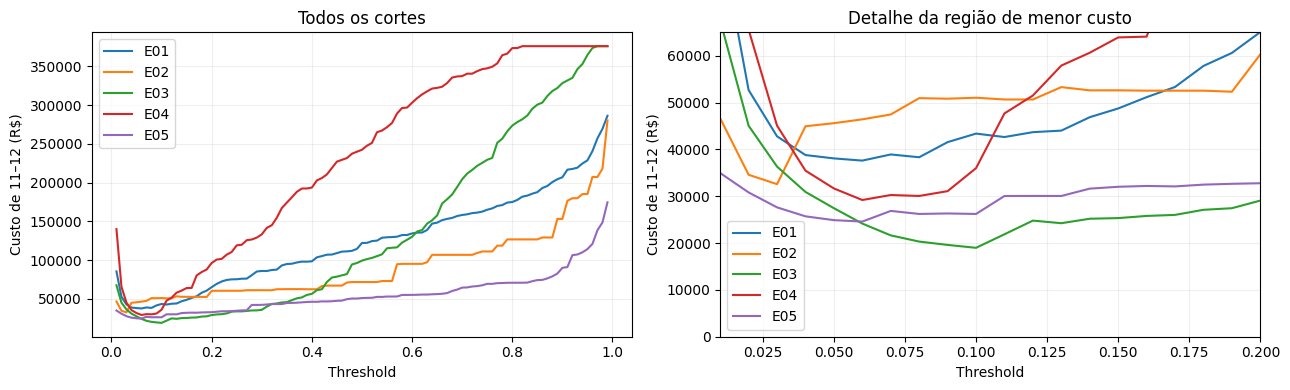

In [13]:
tabela = pd.DataFrame(resultados.values()).sort_values('custo').reset_index(drop=True)
display(tabela[['id','algoritmo','threshold','custo','recall','precision','average_precision','legitimas_bloqueadas','fraude_perdida','taxa_bloqueio']])
vencedor = str(tabela.iloc[0].id)
corte = float(resultados[vencedor]['threshold'])
bloqueio_pix = ((validacao.canal=='pix') & (validacao.valor_transacao>1000)).to_numpy()
baselines = pd.DataFrame([
 {'politica':'Aprovar tudo','custo':custo(y_validacao,np.zeros(len(validacao)),valores)},
 {'politica':'Regra Pix > R$ 1.000','custo':custo(y_validacao,bloqueio_pix,valores)},
 *[{'politica':f'{i} com corte 0,5','custo':medir(y_validacao,scores[i],valores,0.5)['custo']} for i in modelos],
 {'politica':f'{vencedor} com corte escolhido {corte:.2f}','custo':resultados[vencedor]['custo']},
])
display(baselines)
piso = baselines.iloc[:2].custo.min()
assert resultados[vencedor]['custo'] < piso
assert resultados[vencedor]['custo'] < medir(y_validacao,scores[vencedor],valores,.5)['custo']
print('Piso de custo da atividade atendido na validação.')
fig,axes=plt.subplots(1,2,figsize=(13,4))
for i,curva in curvas.items():
    axes[0].plot(curva.threshold,curva.custo,label=i)
    axes[1].plot(curva.threshold,curva.custo,label=i)
axes[0].set(title='Todos os cortes',xlabel='Threshold',ylabel='Custo de 11–12 (R$)')
axes[1].set(title='Detalhe da região de menor custo',xlabel='Threshold',ylabel='Custo de 11–12 (R$)',xlim=(0.01,0.2),ylim=(0,65000))
for ax in axes: ax.legend(); ax.grid(alpha=.2)
fig.tight_layout();fig.savefig(SAIDA/'curvas_custo.png',dpi=140);plt.show()

In [14]:
por_semana=[]
for i in modelos:
    for semana in [11,12]:
        mask=validacao.semana.eq(semana).to_numpy()
        g=validacao.loc[mask]
        m=medir(g.fraude,scores[i][mask],g.valor_transacao,resultados[i]['threshold'])
        por_semana.append({'id':i,'semana':semana,**m})
semanal=pd.DataFrame(por_semana)
display(semanal[['id','semana','custo','recall','precision','legitimas_bloqueadas','fraude_perdida']])
display(curvas[vencedor].loc[(curvas[vencedor].threshold-corte).abs() <= .030001,['threshold','custo','recall','precision','legitimas_bloqueadas','fraude_perdida']])
print('Melhor modelo em cada semana (com os cortes globais):')
display(semanal.loc[semanal.groupby('semana').custo.idxmin(),['id','semana','custo']])

,id,semana,custo,recall,precision,legitimas_bloqueadas,fraude_perdida
0,E01,11,20068.06,0.734628,0.315278,493,12673.06
1,E01,12,17539.99,0.769759,0.346213,423,11194.99
2,E02,11,16686.51,0.857605,0.305652,602,7656.51
3,E02,12,15891.84,0.859107,0.318066,536,7851.84
4,E03,11,11019.25,0.825243,0.488506,267,7014.25
5,E03,12,7966.36,0.838488,0.533917,213,4771.36
6,E04,11,15694.59,0.818770,0.327720,519,7909.59
7,E04,12,13501.65,0.831615,0.349711,450,6751.65
8,E05,11,11439.87,0.834951,0.517034,241,7824.87
9,E05,12,13148.12,0.845361,0.522293,225,9773.12


,threshold,custo,recall,precision,legitimas_bloqueadas,fraude_perdida
6,0.07,21639.75,0.858333,0.397377,781,9924.75
7,0.08,20316.59,0.845000,0.437446,652,10536.59
8,0.09,19604.86,0.835000,0.482659,537,11549.86
9,0.10,18985.61,0.831667,0.509704,480,11785.61
10,0.11,21875.72,0.821667,0.530108,437,15320.72
11,0.12,24794.89,0.811667,0.558486,385,19019.89
12,0.13,24239.89,0.811667,0.583234,348,19019.89


Melhor modelo em cada semana (com os cortes globais):


,id,semana,custo
4,E03,11,11019.25
5,E03,12,7966.36


## 6. Reprodução, rastreabilidade e conferência do modelo salvo

Recarregamos o modelo salvo no MLflow e comparamos suas probabilidades e seu custo. Se a cópia das evidências da primeira rodada estiver disponível, também conferimos os cortes e os custos de todas as cinco configurações. Hashes permitem verificar se o conjunto original é o mesmo. Essas conferências são de reprodutibilidade, não novas evidências de generalização.

In [15]:
recarregado=mlflow.sklearn.load_model(f'runs:/{runs[vencedor]}/modelo')
prob_recarregada=recarregado.predict_proba(X_validacao)[:,list(recarregado.classes_).index(1)]
np.testing.assert_allclose(prob_recarregada,scores[vencedor],rtol=1e-12,atol=1e-12)
assert np.isclose(medir(y_validacao,prob_recarregada,valores,corte)['custo'],resultados[vencedor]['custo'])
print('Modelo recarregado: probabilidades e custo conferidos nas',len(validacao),'transações.')
evidencias_possiveis=[ROOT/'evidencias/experimentos-originais.json',ROOT/'docs/evidencias/experimentos-iniciais.json']
original_path=next((p for p in evidencias_possiveis if p.exists()),None)
if original_path:
    originais=json.loads(original_path.read_text(encoding='utf-8'))
    for r in originais:
        assert np.isclose(resultados[r['id']]['custo'],r['resultado']['custo'],atol=.01)
        assert np.isclose(resultados[r['id']]['threshold'],r['resultado']['threshold'])
    print('Cortes e custos reproduzidos para as cinco famílias em relação à primeira rodada.')
else:
    print('Sem arquivo opcional da primeira rodada; esta execução mantém seus próprios resultados e hashes.')
tabela.to_csv(SAIDA/'comparacao.csv',index=False)
semanal.to_csv(SAIDA/'por_semana.csv',index=False)
baselines.to_csv(SAIDA/'baselines.csv',index=False)
(SAIDA/'resultados.json').write_text(json.dumps(list(resultados.values()),indent=2,ensure_ascii=False),encoding='utf-8')
manifesto['run_ids']=runs
manifesto['candidato']=vencedor
(SAIDA/'manifesto.json').write_text(json.dumps(manifesto,indent=2,ensure_ascii=False),encoding='utf-8')

Modelo recarregado: probabilidades e custo conferidos nas 39497 transações.
Cortes e custos reproduzidos para as cinco famílias em relação à primeira rodada.


4362

## 7. Resumo final — decisão, alternativas e limites

A célula seguinte gera o texto da decisão a partir das métricas realmente calculadas. O mesmo texto é salvo em arquivo para acompanhar o notebook na pasta de entrega. A seleção não é promoção automática.

In [16]:
def reais(x):
    return 'R$ '+f'{x:,.2f}'.replace(',','X').replace('.',',').replace('X','.')
m=resultados[vencedor]
bloqueadas_legitimas=validacao.loc[(validacao.fraude.to_numpy()==0) & (scores[vencedor]>=corte)]
clientes_afetados=int(bloqueadas_legitimas.id_cliente.nunique())
custo_regra=float(baselines.loc[baselines.politica.eq('Regra Pix > R$ 1.000'),'custo'].iloc[0])
custo_05=medir(y_validacao,scores[vencedor],valores,.5)['custo']
economia=custo_regra-m['custo']
ranking=max(resultados,key=lambda i:resultados[i]['average_precision'])
linhas=['# Resumo final — escolha do candidato antifraude','',
 f"**Escolha:** {m['algoritmo']} ({vencedor}), com threshold global **{corte:.2f}**. Bloquear para verificação quando score >= threshold.",'',
 '## Por que escolhemos este modelo','',
 f"Foi o menor custo observado entre cinco famílias e 99 cortes por família, nas mesmas semanas 11–12: **{reais(m['custo'])}** em duas semanas, média de **{reais(m['custo']/2)} por semana**. A regra atual de Pix custou {reais(custo_regra)}; a economia observada foi **{reais(economia)} ({100*economia/custo_regra:.2f}%)**. O próprio modelo a 0,5 custou {reais(custo_05)}.",'',
 f"O candidato bloqueou {m['legitimas_bloqueadas']} transações legítimas, com custo de atrito de {reais(15*m['legitimas_bloqueadas'])}, e deixou passar {reais(m['fraude_perdida'])} em fraude. Recall: {m['recall']:.2%}; precision: {m['precision']:.2%}; average precision: {m['average_precision']:.4f}. As 480 transações legítimas bloqueadas afetaram {clientes_afetados} clientes distintos. `id_cliente` foi usado somente no relatório de impacto; não entrou nas features, e o custo de atrito continua sendo por transação.",'',
 '## Alternativas e motivos de descarte','']
for i,r in resultados.items():
    linhas.append(f"- {i} — {r['algoritmo']}: custo {reais(r['custo'])}, corte {r['threshold']:.2f}; "+('selecionado por menor custo.' if i==vencedor else 'não selecionado nesta rodada por custo superior.'))
linhas += ['',f"A maior average precision foi de {ranking} ({resultados[ranking]['average_precision']:.4f}); ela mede ranking, não o prejuízo monetário. Por isso não substitui a função de custo.",'','## Consistência por semana','']
for _,r in semanal[semanal.id.eq(vencedor)].iterrows():
    linhas.append(f"- Semana {int(r.semana)}: custo {reais(r.custo)}, {int(r.legitimas_bloqueadas)} legítimas bloqueadas e {reais(r.fraude_perdida)} em fraude aprovada.")
linhas += ['','## O que foi documentado e reproduzido','',
 'Hipóteses iniciais, configurações, contrato, hashes dos dados, auditoria, divisão temporal, custo, baselines, curvas, métricas por semana, tempos e run_ids estão no notebook e nos arquivos de resultados. A falha técnica anterior E01 foi preservada separadamente; a reprodução usa as mesmas hipóteses e não apaga o histórico.',
 '',f"Execução UTC: {EXECUCAO}. Run E03 criada nesta reprodução: `{runs[vencedor]}`. Esta run serve à reprodução e não é a origem da versão em produção. `antifraude@champion` v1 foi promovida da run original E03 `ff48c43154624ec9a1e3d16688909ef3`, conforme decisão aprovada; reproduzir não troca o alias.",'',
 '## Limitações e próximos passos','',
 'As semanas 11–12 foram usadas para escolher modelo e corte: são validação de seleção, não teste independente. A redução observada não é garantia de economia futura. Não demonstramos a ausência de vazamento upstream nas médias e contagens históricas. A política de corte global simplifica custos que dependem do valor de cada transação. O monitoramento, referência, promoção/alias champion, paridade com a API e pacote integral estão concluídos e documentados no notebook de atividade `parte1.ipynb` e em `docs/status-etapas.md`. Este resumo registra a reprodução da análise, não é uma avaliação independente.'
]
resumo='\n'.join(linhas)+'\n'
(SAIDA/'RESUMO_ESCOLHA.md').write_text(resumo,encoding='utf-8')
display(Markdown(resumo))
print('Arquivos desta execução:',SAIDA.name)

# Resumo final — escolha do candidato antifraude

**Escolha:** RandomForestClassifier (E03), com threshold global **0.10**. Bloquear para verificação quando score >= threshold.

## Por que escolhemos este modelo

Foi o menor custo observado entre cinco famílias e 99 cortes por família, nas mesmas semanas 11–12: **R$ 18.985,61** em duas semanas, média de **R$ 9.492,81 por semana**. A regra atual de Pix custou R$ 225.349,79; a economia observada foi **R$ 206.364,18 (91.58%)**. O próprio modelo a 0,5 custou R$ 99.338,94.

O candidato bloqueou 480 transações legítimas, com custo de atrito de R$ 7.200,00, e deixou passar R$ 11.785,61 em fraude. Recall: 83.17%; precision: 50.97%; average precision: 0.8130. As 480 transações legítimas bloqueadas afetaram 476 clientes distintos. `id_cliente` foi usado somente no relatório de impacto; não entrou nas features, e o custo de atrito continua sendo por transação.

## Alternativas e motivos de descarte

- E01 — LogisticRegression: custo R$ 37.608,05, corte 0.06; não selecionado nesta rodada por custo superior.
- E02 — DecisionTreeClassifier: custo R$ 32.578,35, corte 0.03; não selecionado nesta rodada por custo superior.
- E03 — RandomForestClassifier: custo R$ 18.985,61, corte 0.10; selecionado por menor custo.
- E04 — ExtraTreesClassifier: custo R$ 29.196,24, corte 0.06; não selecionado nesta rodada por custo superior.
- E05 — HistGradientBoostingClassifier: custo R$ 24.587,99, corte 0.06; não selecionado nesta rodada por custo superior.

A maior average precision foi de E05 (0.8320); ela mede ranking, não o prejuízo monetário. Por isso não substitui a função de custo.

## Consistência por semana

- Semana 11: custo R$ 11.019,25, 267 legítimas bloqueadas e R$ 7.014,25 em fraude aprovada.
- Semana 12: custo R$ 7.966,36, 213 legítimas bloqueadas e R$ 4.771,36 em fraude aprovada.

## O que foi documentado e reproduzido

Hipóteses iniciais, configurações, contrato, hashes dos dados, auditoria, divisão temporal, custo, baselines, curvas, métricas por semana, tempos e run_ids estão no notebook e nos arquivos de resultados. A falha técnica anterior E01 foi preservada separadamente; a reprodução usa as mesmas hipóteses e não apaga o histórico.

Execução UTC: 20261110T184047_082995Z. Run E03 criada nesta reprodução: `3d3afdd446784c8aa9a8a7737fe5ae50`. Esta run serve à reprodução e não é a origem da versão em produção. `antifraude@champion` v1 foi promovida da run original E03 `ff48c43154624ec9a1e3d16688909ef3`, conforme decisão aprovada; reproduzir não troca o alias.

## Limitações e próximos passos

As semanas 11–12 foram usadas para escolher modelo e corte: são validação de seleção, não teste independente. A redução observada não é garantia de economia futura. Não demonstramos a ausência de vazamento upstream nas médias e contagens históricas. A política de corte global simplifica custos que dependem do valor de cada transação. O monitoramento, referência, promoção/alias champion, paridade com a API e pacote integral estão concluídos e documentados no notebook de atividade `parte1.ipynb` e em `docs/status-etapas.md`. Este resumo registra a reprodução da análise, não é uma avaliação independente.


Arquivos desta execução: 20261110T184047_082995Z


In [17]:
# Impacto em pessoas: IDs entram somente na contagem de clientes, fora das features.
from pathlib import Path
import pandas as pd
from IPython.display import display

raiz_local = next(p for p in [Path.cwd(), Path.cwd().parent] if (p/'dados/transacoes_semanas_01_12.csv').exists())
ref_local = next(p for p in [raiz_local/'dados/referencia_e03_semanas_11_12.csv', raiz_local/'artefatos/referencia_e03_semanas_11_12.csv'] if p.exists())
ref_clientes = pd.read_csv(ref_local, sep=';', dtype={'id_transacao':str})
clientes = pd.read_csv(raiz_local/'dados/transacoes_semanas_01_12.csv', usecols=['id_transacao','id_cliente'], dtype={'id_transacao':str,'id_cliente':str})
impacto_clientes = ref_clientes.merge(clientes, on='id_transacao', how='left', validate='one_to_one')
impacto_clientes = impacto_clientes[(impacto_clientes.fraude==0) & (impacto_clientes.score>=0.10)]
impacto_semana = impacto_clientes.groupby('semana').agg(transacoes=('id_transacao','size'),clientes_distintos=('id_cliente','nunique'))
assert len(impacto_clientes)==480 and impacto_clientes.id_cliente.nunique()==476
display(impacto_semana)
print(f"No período: 480 transações legítimas bloqueadas atingiram 476 clientes distintos; dois clientes aparecem nas duas semanas.")
if 'SAIDA' in globals():
    resumo_path=SAIDA/'RESUMO_ESCOLHA.md'
    with resumo_path.open('a',encoding='utf-8') as f:
        f.write('\n\n## Clientes legítimos impactados\n\nNo corte escolhido (0,10), 480 transações legítimas foram bloqueadas, afetando 476 clientes distintos nas semanas 11–12. Foram 266 clientes na semana 11 e 212 na semana 12; dois clientes aparecem em ambas. O custo de atrito continua calculado por transação (R$ 15 cada), conforme a demanda. `id_cliente` foi usado somente para deduplicar o relatório e não entrou nas features.\n')

,transacoes,clientes_distintos
semana,,
11,267,266
12,213,212


No período: 480 transações legítimas bloqueadas atingiram 476 clientes distintos; dois clientes aparecem nas duas semanas.
